# Tiamat - O estágio de vida das estrelas

## Importando tudo

In [114]:
from astropy.io import fits
from astropy.table import Table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.decomposition import PCA

from sklearn.metrics import classification_report

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    BaggingClassifier,
    StackingClassifier
)

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Semente aleatória
RANDOM_SEED = 3001

In [115]:
caminho = "table1.fits"

with fits.open(caminho, memmap=True) as arquivo:
    arquivo.info()

Filename: table1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      16   (5773,)   uint8   
  1  Joined        1 BinTableHDU    126   117446R x 43C   [K, D, D, D, D, E, E, E, 9A, L, L, D, D, D, D, 7A, 10A, I, I, D, D, D, 26A, E, E, E, E, E, E, E, E, J, J, J, J, J, 18A, 19A, J, K, 18A, 20A, K]   


## Tratando de maneira básica

In [116]:
# Lê a tabela da extensão 1
tabela = Table.read(caminho, hdu=1)

print("\nDimensão da tabela Astropy:")
print(f"Linhas: {len(tabela)}")
print(f"Colunas: {len(tabela.colnames)}")

print("\nNomes das colunas:")
print(tabela.colnames)

# Converte para pandas
df = tabela.to_pandas()

# Converte strings em bytes, quando necessário
for coluna in df.select_dtypes(include="object").columns:
    df[coluna] = df[coluna].map(
        lambda valor: (
            valor.decode("utf-8").strip()
            if isinstance(valor, bytes)
            else valor.strip()
            if isinstance(valor, str)
            else valor
        )
    )

df.head()


Dimensão da tabela Astropy:
Linhas: 117446
Colunas: 43

Nomes das colunas:
['SPICY', 'ra', 'dec', 'l', 'b', 'p1', 'p2', 'p3', 'class', 'silicate', 'pah', 'alpha', 'alpha_8', 'alpha_24', 'alpha_w4', 'env', 'group', 'var', 'nr', 'r', 'sigmar', 'skewnessr', 'Spitzer', 'mag3_6', 'e_mag3_6', 'mag4_5', 'e_mag4_5', 'mag5_8', 'e_mag5_8', 'mag8_0', 'e_mag8_0', 'csf', 'm3_6', 'm4_5', 'm5_8', 'm8_0', '2MASS', 'UKIDSS', 'VIRAC', 'GaiaDR2', 'MIPS', 'AllWISE', 'ZTFDR3']


,SPICY,ra,dec,l,b,p1,p2,p3,class,silicate,...,m4_5,m5_8,m8_0,2MASS,UKIDSS,VIRAC,GaiaDR2,MIPS,AllWISE,ZTFDR3
0,1,125.664811,-37.551349,255.975183,-0.253369,0.71,NaN,NaN,ClassII,False,...,2,2,2,08223956-3733048,NaN,<NA>,5541983493883598848,NaN,J082239.55-373304.5,<NA>
1,2,125.795513,-37.585000,256.062070,-0.187675,0.69,NaN,NaN,ClassII,False,...,2,2,2,08231092-3735060,NaN,<NA>,5541980848188474368,NaN,J082310.90-373505.9,<NA>
2,3,125.860244,-37.577463,256.085297,-0.141319,0.87,NaN,NaN,FS,False,...,2,2,2,08232646-3734388,NaN,<NA>,5541969475116705792,NaN,J082326.45-373438.8,<NA>
3,4,125.946863,-37.770809,256.282985,-0.196119,0.53,NaN,NaN,ClassI,False,...,4,2,4,NaN,NaN,<NA>,<NA>,NaN,J082347.25-374615.0,<NA>
4,5,126.003155,-37.126075,255.780917,0.210831,0.54,NaN,NaN,FS,False,...,2,2,2,08240071-3707341,NaN,<NA>,5542020537982099456,NaN,J082400.75-370733.7,<NA>


## Análise exploratória dos dados

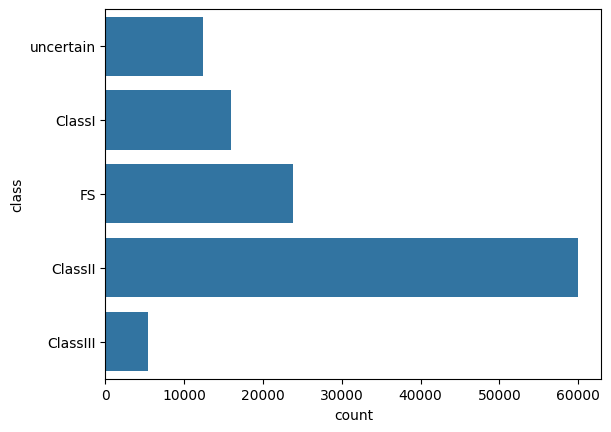

In [117]:
sns.countplot(
    df["class"],
    order=["uncertain", "ClassI", "FS", "ClassII", "ClassIII"]
)

plt.show()

In [118]:
print("\nDistribuição de classes:")
print(df["class"].value_counts(dropna=False))

print("\nAtributos com mais valores ausentes:")
print(
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .head(20)
)


Distribuição de classes:
class
ClassII      59949
FS           23810
ClassI       15943
uncertain    12392
ClassIII      5352
Name: count, dtype: int64

Atributos com mais valores ausentes:
sigmar       93.541713
nr           93.541713
var          93.541713
r            93.541713
skewnessr    93.541713
ZTFDR3       93.541713
alpha_w4     92.140218
alpha_24     69.482996
MIPS         69.482996
GaiaDR2      68.987450
p2           65.190811
UKIDSS       64.921751
AllWISE      63.812305
p3           52.313404
VIRAC        52.186537
group        50.544080
2MASS        44.726938
p1           12.621119
alpha_8       8.985406
mag8_0        8.985406
dtype: float64


Antes de continuar, vamos explicar o que cada coluna é:

- ``SPICY``: Um tipo de índice para cada *Yong Stellar Object* (YSO);
- ``ra``: Ascensão reta (deg) - como uma longitude celeste;
- ``dec``: Declinação (deg) - como uma latitude celeste;
- ``l``: Longitude galáctica (deg) - usa a Via Láctea como referência;
- ``b``: Latitude galáctica (deg) - usa a Via Láctea como referência;
- ``p1``: *Score* da YSO por floresta aleatória, a partir de fotometria IRAC+2MASS - não será usado por risco de vazamento;
- ``p2``: *Score* da YSO por floresta aleatória, a partir de forometria IRAC+UKIDSS - não será usado por risco de vazamento;
- ``p3``: *Score* da YSO por floresta aleatória, a partir de fotometria IRAC+VVV - não será usado por risco de vazamento;
- ``class`` (**nosso *target***): Classe da YSO;
- ``silicate``: Sinaliza possível presença intensa de silicatos;
- ``pah``: Sinaliza possível presença intensa de Hidrocarbonetos Aromáticos Plolicíclicos (PAH);
- ``alpha``: Índice espectral usado pela classe YSO - não será usado por risco de vazamento;
- ``alpha_8``: Índice espectral derivado da cor 4.5-8.0 - não será usado por risco de vazamento;
- ``alpha_24``: Índice espectral derivado da cor 4.5-24 - não será usado por risco de vazamento;
- ``alpha_w4``: Índice espectral derivado da cor 4.5-W4 - não será usado por rixco de vazamento;
- ``env``: Classificação do ambiente da YSO;
- ``group``: Grupo HDBSCAN ao qual a estrela é atribuida;
- ``var``: Indicador de variabilidade luminosa da YSO;
- ``nr``: Número de boas observações de bandas-r ZTF usadas - usada para determinar a variabilidade luminosa;
- ``r``: Magnitude média de ZTF na banda-r;
- ``sigmar``: Desvio padrão da curva de luz ZTF na banda-r;
- ``skewnwessr``: Assimetria da curva de luz ZTF na banda-r;
- ``Spitzer``: Designação da fonte do telescópio Spitzer;
- ``mag3_6``: Magnitude do canal 1 do Spizer/IRAC;
- ``e_mag3_6``: Erro no canal 1 da Spitzer/IRAC;
- ``mag4_5``: Magnitude do canal 2 do Spitzer/IRAC;
- ``e_mag4_5``: Erro no canal 2 da Spitzer/IRAC;
- ``mag5_8``: Magnitude do canal 3 do Spitzer/IRAC;
- ``e_mag5_8``: Erro no canal 3 do Spitzer/IRAC;
- ``mag8_0``: Magnitude do canal 4 do Spitzer/IRAC;
- ``e_mag8_0``: Erro no canal 4 do Spitzer/IRAC;
- ``csf``: Indicador de possível contaminação;
- ``m3_6``: Número de detecções na banda de 3.6 mícrons;
- ``m4_5``: Número de detecções na banda de 4.5 mícrons;
- ``m5_8``: Número de detecções na banda de 5.8 mícrons;
- ``m8_0``: Nímero de detecções na banda de 8.0 mícrons;
- ``TWOMASS``: Designação da fonte 2MASS;
- ``UKIDSS``: Designação da fonte UKDISS;
- ``VIRAC``: Designação da fonte VIRAC;
- ``GaiaDR2``: Designação da fonte Gaia DR2;
- ``MIPS``: Designação da fonte Spitzer/MIPS;
- ``AIIWISE``: Designação da fonte AIIWISE;
- ``ZTFDR3``: Designação da fonte ZTF DR3.

Aqui vale notar algumas coisas, primeiro que algumas das colunas só representam designações, como índices, além disso, precisamos tirar alguns atributos que possam gerar *target leakage*, como ``p1``, ``p2`` e ``p3``. Outros serão usados como teste, em diferentes experimentos, para testar o desempenho.

Então vamos definir as colunas que iremos usar, por enquanto.

In [119]:
ATRIBUTOS = [
    "ra", "dec", "l", "b", "silicate",
    "pah", "env", "mag3_6", "e_mag3_6",
    "mag4_5", "e_mag4_5", "mag5_8", "e_mag5_8", "mag8_0",
    "e_mag8_0", "csf", "m3_6", "m4_5", "m5_8", "m8_0"
]
TARGET = ["class"]

Algo importante é que esses são nossa **base**, pois ainda precisamos analisar os dados, entender como estão distribuidos e seu comportamento, para só então começar a modelagem. Outra coisa importante é que, por perigo de vazamento espacial, a divisão de treino e teste será feita agrupando estrelas de mesmo ``group`` e serão feitos dois *pipelines*, um usando somente as variáveis fotométricas e outro adicionando espaço, buscando analisar como fica o comportamento dos modelos.

Agora vamos explorar os dados realmente. Primeiro, vamos ver a quantidade de grupos e sua distribuição.

### Gropos

<Axes: xlabel='count', ylabel='group'>

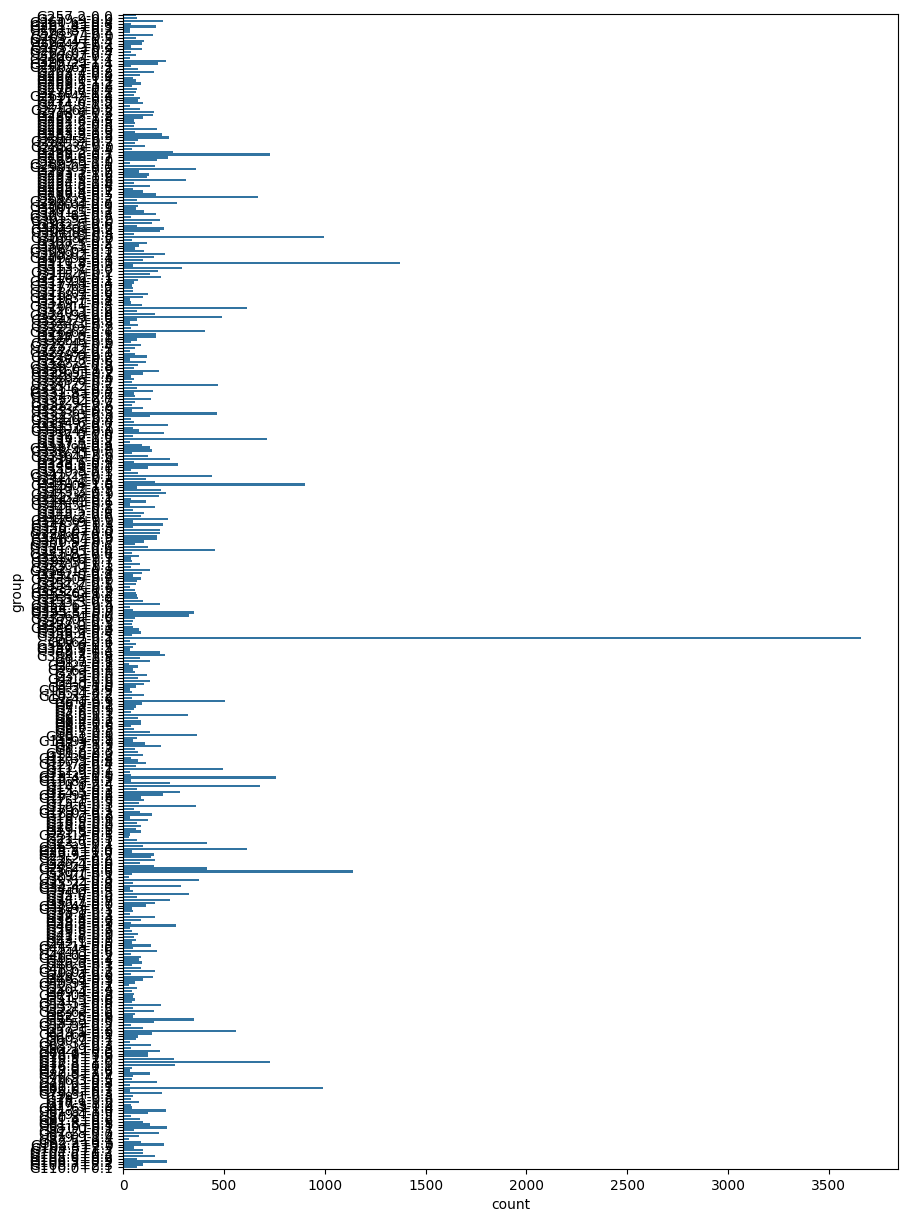

In [120]:
plt.figure(figsize=(10, 15))
sns.countplot(
    df["group"]
)

Bem, como podemos ver, temos alguns grupos com pouquíssimos representantes, e outros com uma quantidade razoável. Isso nos ajuda a entender uma coisa, por mais que os dados possam estar relacionados espacialmente, há pouca correlação, o que faz sentido, uma vez que essa correlação seria principalmente relacionada à gravidade, uma força fraca. Ainda assim, é importante tratar com cuidado os dados, pois existem complexos de formação estelar, que podem gerar vazamento espacial, então é melhor tomar cuidado.

Agora vamos ver os ambientes de cada YSO.

### Ambiente infravermelho

Algo importante de se deixar claro é que o ambiente, nesse caso, diz sobre o ambiente infravermelho nos arredores da estrela, não sobre características como densidade de gás ou coisas do tipo. Com isso, temos 4 possíveis classificações:

- ``EnvI``: Nebulosidade ausente ou mínima - é possível associar ambientes pouco nebulosos a estrelas já mias evoluidas, mas há pouca correlação, logo não é possível tirar muitas conclusões;
- ``EnvII``: Estado intermediário, contendo, geralmente, ambientes entre regiões sem nebulosidade e regiões mais nebulosas;
- ``EnvIII``: Ambientes difusos, com grande nebulosidade, caracterizando grande quantidade de estruturas no infravermelho - também é possível associar esses ambientes a estrelas mais ativas, mas ainda assim podem haver outras interferências;
- ``Outliers``: É uma classificação associada a erros, como má formação da imagem ou da banda espectral, problemas de processamento, etc.

<Axes: xlabel='count', ylabel='env'>

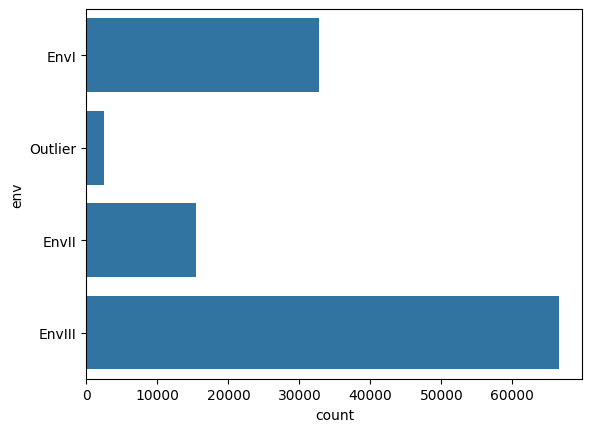

In [121]:
sns.countplot(
    df["env"]
)

Mas aqui temos um pequeno problema. Os algoritmos usados não reconhecem variáveis do tipo ``String``, então será preciso fazer uma transformação simbólico-numérica. Mas, para isso, precisamos definir qual estratégia usar, ou considerando uma variável nominal, ou ordinal. Para tal, iremos, ao invés de definir de antemão, fazer um teste para cada, pois, mesmo que os ambientes sejam classificados em ordem, há certa ambiguidade no ambiente ``EnvII``, por ser um intermediário - ou mesmo somente uma incapacidade de classificar em ``EnvI`` ou ``EnvIII`` - podendo não ser necessariamente ordinal.

Agora vamos limpar o dataset do que já foi definido que irá sair.

In [122]:
df_tratado = df.reindex(ATRIBUTOS + ["group"] + TARGET, axis=1)

df_tratado = df_tratado.dropna(subset=ATRIBUTOS)

Já tiramos os dados faltantes. Mas ainda temos um problema, ambientes do tipo *outlier*, que não são um tipo de ambiente na verdade, mas erros. Portanto precisamos retirar os exemplos com esses problemas de análise!

In [123]:
filtro1 = df_tratado["env"] != "Outlier"
filtro2 = df_tratado["class"] != "uncertain"
filtro = filtro1 & filtro2

df_tratado = df_tratado.loc[filtro]

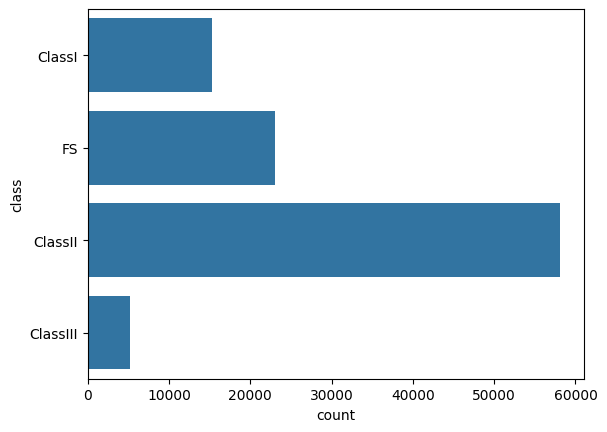

In [124]:
sns.countplot(
    df_tratado["class"],
    order=["ClassI", "FS", "ClassII", "ClassIII"]
)

plt.show()

In [125]:
print("\nDistribuição de classes:")
print(df_tratado["class"].value_counts(dropna=False))


Distribuição de classes:
class
ClassII     58114
FS          23068
ClassI      15253
ClassIII     5211
Name: count, dtype: int64


Aqui temos alguns pontos importantes, primeiro, temos muitos valores ausentes no atributo ``group`` - que significa que eles simplesmente não têm grupo - e, além disso, essa não é uma medida física propriamente dita, mas um agrupamento feito pelo HDBSCAN, e pode gerar vazamento espacial. Então esse atributo só será usado para fazer a divisão de treino e teste do dataset, e depois ele não será usado no treinamento.

### Visualizando algumas coisas

In [126]:
class_I = df_tratado["class"] == "ClassI"
FS = df_tratado["class"] == "FS"
class_II = df_tratado["class"] == "ClassII"
class_III = df_tratado["class"] == "ClassIII"

df_classI = df_tratado.loc[class_I]
df_FS = df_tratado.loc[FS]
df_classII = df_tratado.loc[class_II]
df_classIII = df_tratado.loc[class_III]

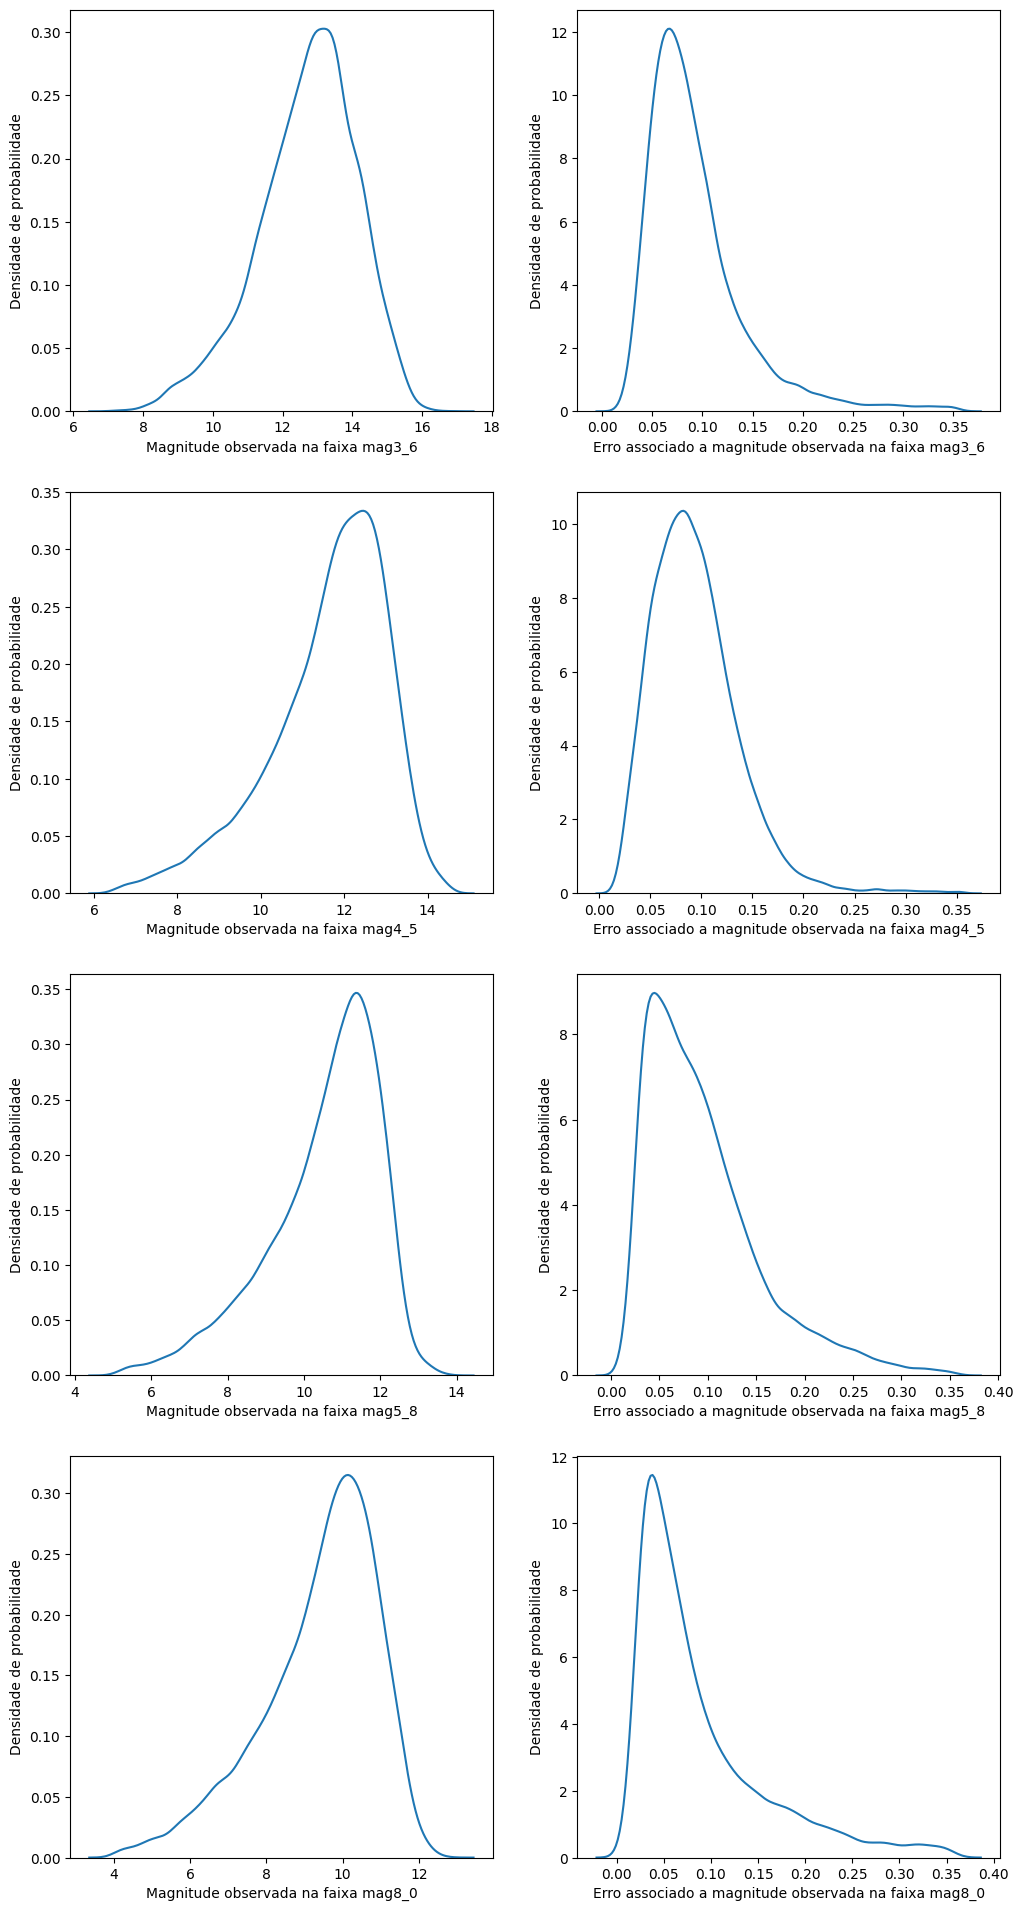

In [127]:
# Análise da classe I
EIXOS = ["mag3_6", "e_mag3_6", "mag4_5", "e_mag4_5", "mag5_8", "e_mag5_8", "mag8_0", "e_mag8_0"]

figs, axis = plt.subplots(nrows=4, ncols=2, figsize=(12, 24))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1],
    [3,0], [3,1]
]

for pos, mag in zip(eixos, EIXOS):
    ax = axis[pos[0], pos[1]]
    sns.kdeplot(
        data=df_classI,
        x=mag,
        label=mag,
        ax=ax
    )
    # ax.set_title(f"Distribuição de densidade de probabilidade de magnitude da faixa {mag} para YSOs de Classe I")

    if mag[0] == "e":
        ax.set_xlabel(f"Erro associado a magnitude observada na faixa {mag.replace("e_", "")}")
    else:
        ax.set_xlabel(f"Magnitude observada na faixa {mag}")
    ax.set_ylabel("Densidade de probabilidade")

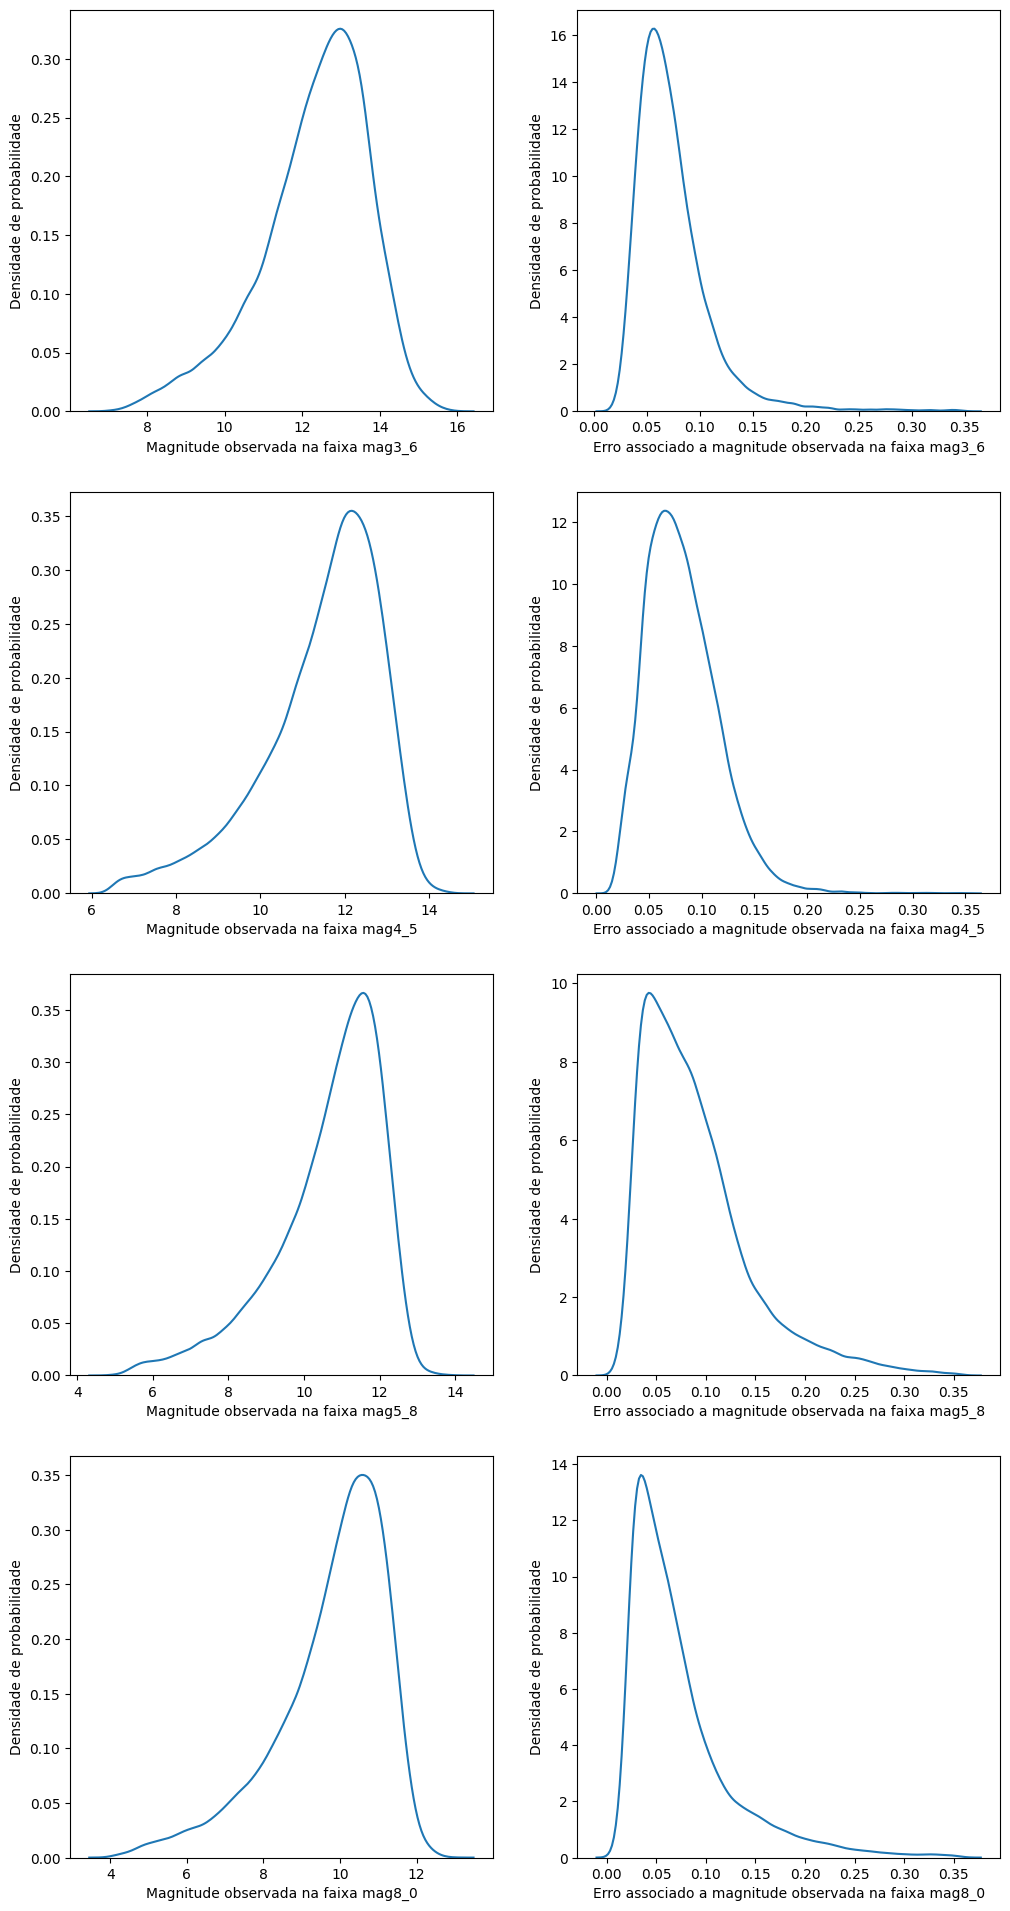

In [128]:
# Análise da classe FS
EIXOS = ["mag3_6", "e_mag3_6", "mag4_5", "e_mag4_5", "mag5_8", "e_mag5_8", "mag8_0", "e_mag8_0"]

figs, axis = plt.subplots(nrows=4, ncols=2, figsize=(12, 24))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1],
    [3,0], [3,1]
]

for pos, mag in zip(eixos, EIXOS):
    ax = axis[pos[0], pos[1]]
    sns.kdeplot(
        data=df_FS,
        x=mag,
        label=mag,
        ax=ax
    )
    # ax.set_title(f"Distribuição de densidade de probabilidade de magnitude da faixa {mag} para YSOs de Classe I")

    if mag[0] == "e":
        ax.set_xlabel(f"Erro associado a magnitude observada na faixa {mag.replace("e_", "")}")
    else:
        ax.set_xlabel(f"Magnitude observada na faixa {mag}")
    ax.set_ylabel("Densidade de probabilidade")

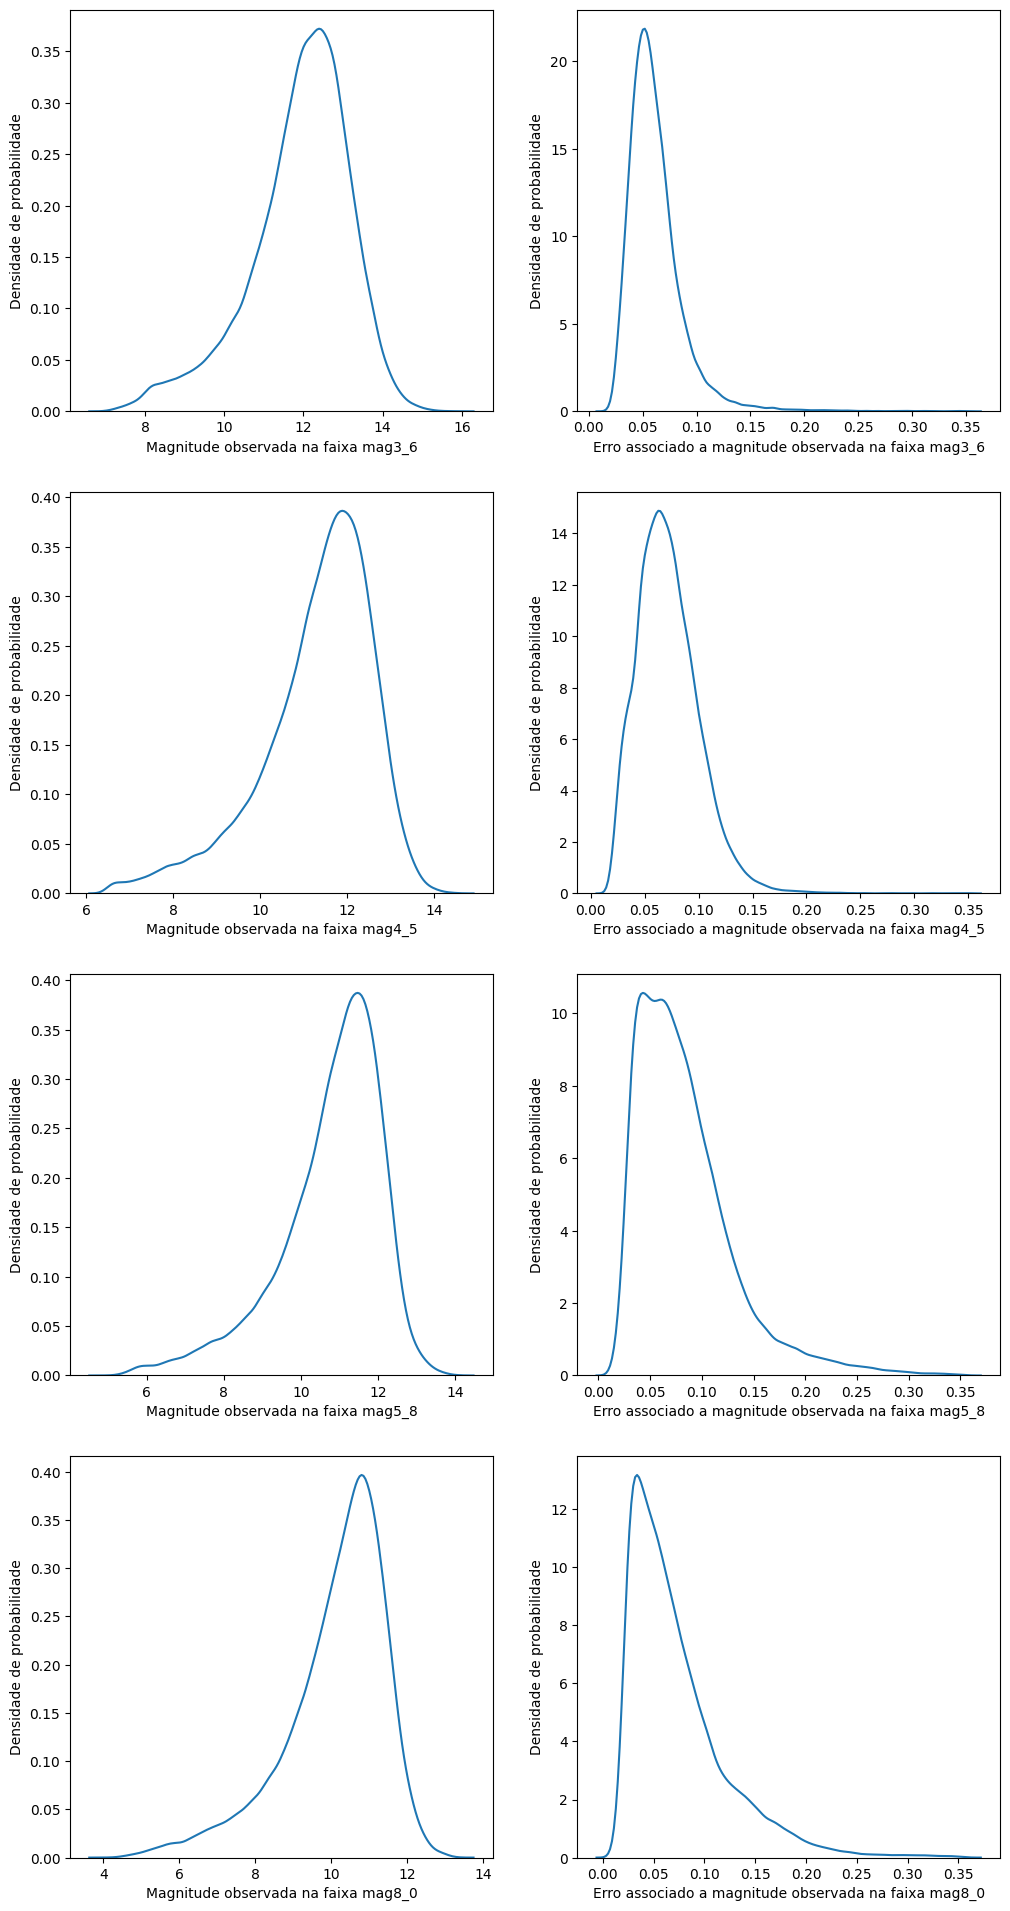

In [129]:
# Análise da classe II
EIXOS = ["mag3_6", "e_mag3_6", "mag4_5", "e_mag4_5", "mag5_8", "e_mag5_8", "mag8_0", "e_mag8_0"]

figs, axis = plt.subplots(nrows=4, ncols=2, figsize=(12, 24))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1],
    [3,0], [3,1]
]

for pos, mag in zip(eixos, EIXOS):
    ax = axis[pos[0], pos[1]]
    sns.kdeplot(
        data=df_classII,
        x=mag,
        label=mag,
        ax=ax
    )
    # ax.set_title(f"Distribuição de densidade de probabilidade de magnitude da faixa {mag} para YSOs de Classe I")

    if mag[0] == "e":
        ax.set_xlabel(f"Erro associado a magnitude observada na faixa {mag.replace("e_", "")}")
    else:
        ax.set_xlabel(f"Magnitude observada na faixa {mag}")
    ax.set_ylabel("Densidade de probabilidade")

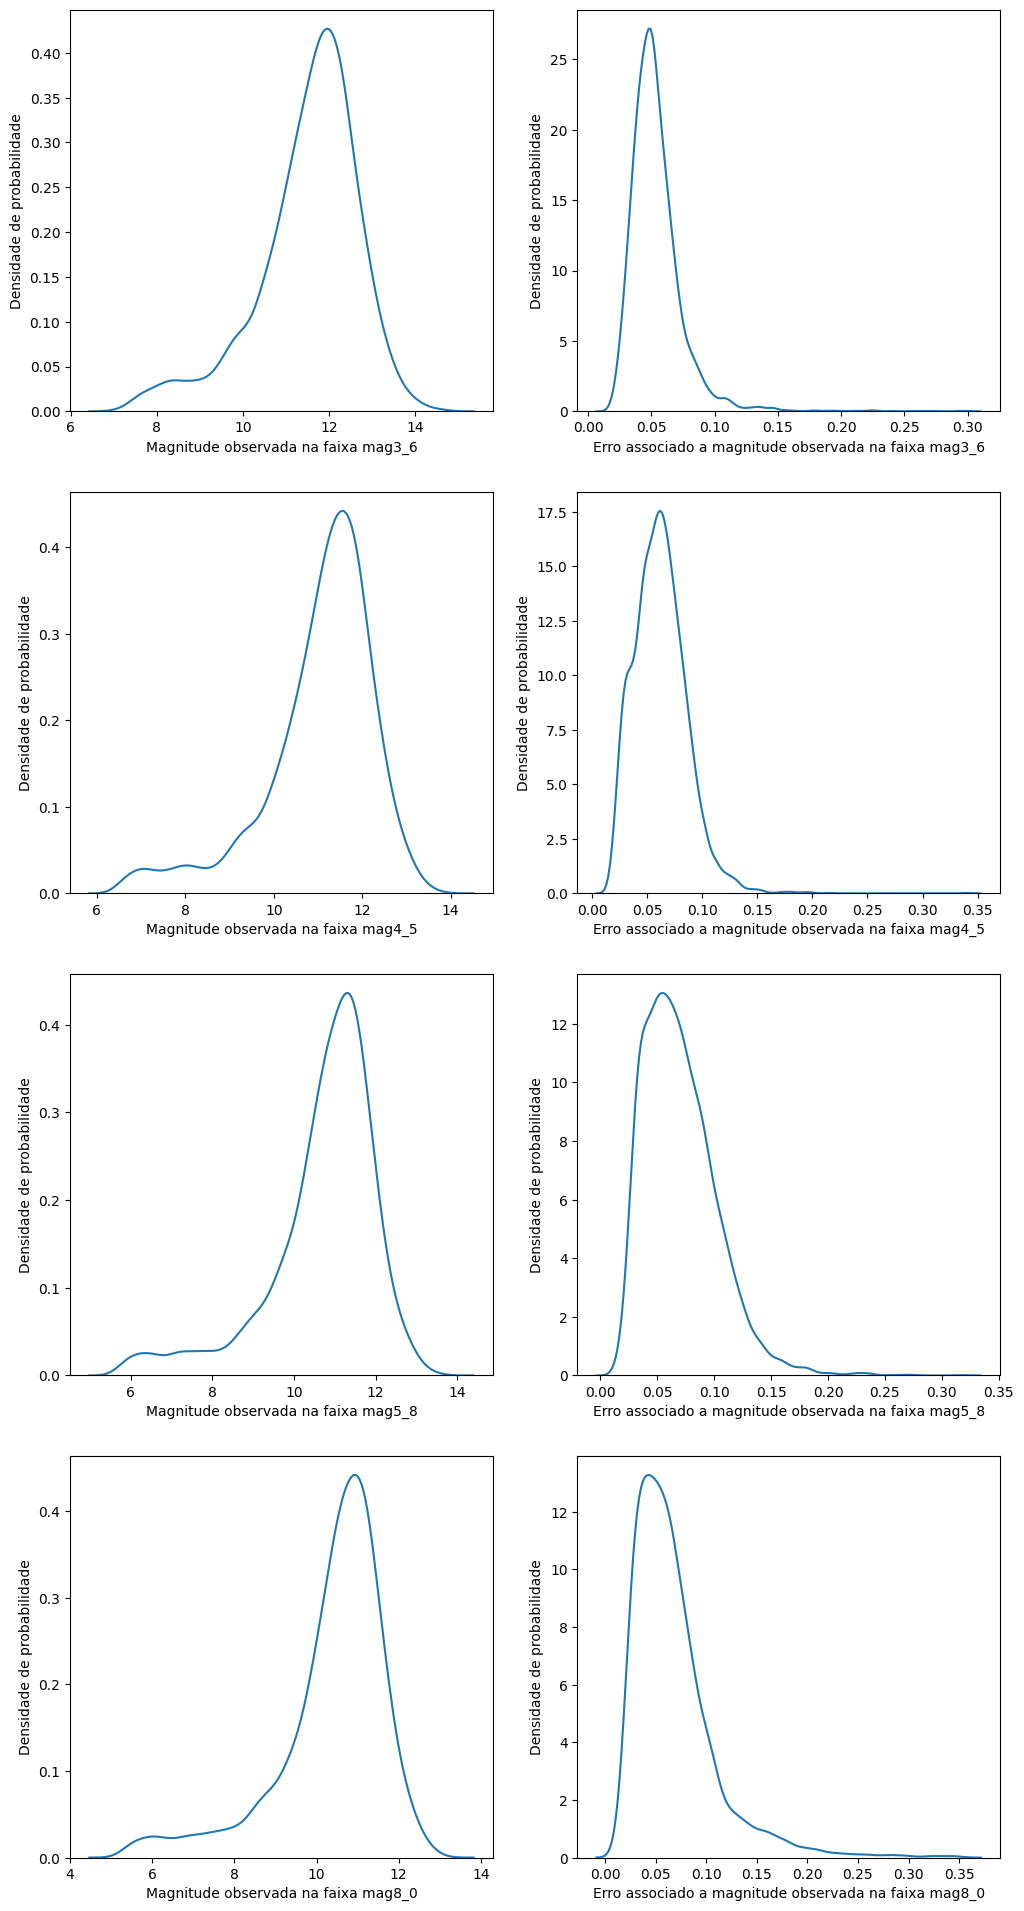

In [130]:
# Análise da classe III
EIXOS = ["mag3_6", "e_mag3_6", "mag4_5", "e_mag4_5", "mag5_8", "e_mag5_8", "mag8_0", "e_mag8_0"]

figs, axis = plt.subplots(nrows=4, ncols=2, figsize=(12, 24))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1],
    [2,0], [2,1],
    [3,0], [3,1]
]

for pos, mag in zip(eixos, EIXOS):
    ax = axis[pos[0], pos[1]]
    sns.kdeplot(
        data=df_classIII,
        x=mag,
        label=mag,
        ax=ax
    )
    # ax.set_title(f"Distribuição de densidade de probabilidade de magnitude da faixa {mag} para YSOs de Classe I")

    if mag[0] == "e":
        ax.set_xlabel(f"Erro associado a magnitude observada na faixa {mag.replace("e_", "")}")
    else:
        ax.set_xlabel(f"Magnitude observada na faixa {mag}")
    ax.set_ylabel("Densidade de probabilidade")

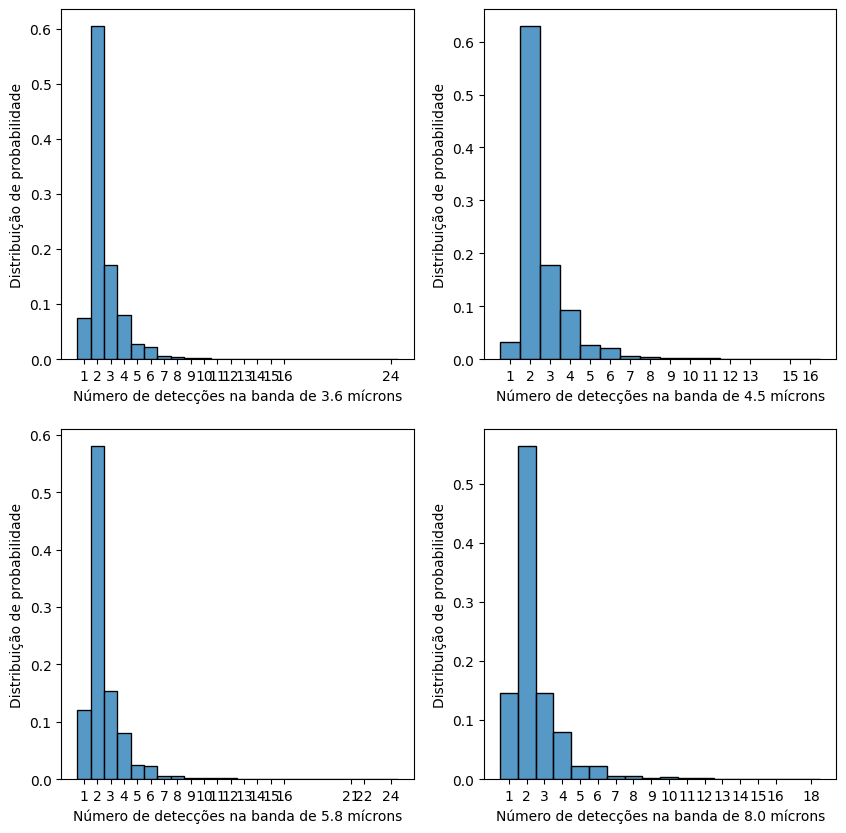

In [131]:
EIXOS = ["m3_6", "m4_5", "m5_8", "m8_0"]

figs, axis = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))

eixos = [
    [0,0], [0,1],
    [1,0], [1,1]
]

for pos, n_mag in zip(eixos, EIXOS):
    ax = axis[pos[0], pos[1]]
    sns.histplot(
        data=df_classI,
        stat="probability",
        discrete=True,
        x=n_mag,
        label=n_mag,
        ax=ax
    )

    banda = n_mag.replace("m", "")
    banda = banda.replace("_", ".")
    
    ax.set_xlabel(f"Número de detecções na banda de {banda} mícrons")
    ax.set_ylabel("Distribuição de probabilidade")
    ax.set_xticks(np.unique(df_classI[n_mag]))

plt.show()

## Últimos tratamentos

### Tratando desbalanceamento

Antes de tudo, precisamos tratar um problema crítico, desbalanceamento de dados, pois, como é possível visualizar no gráfico abaixo, há pouquíssimos representantes da Classe III, ao passo que mais da metade do dataset é composto por estrelas da Classe II. Para resolver esse problema, iremos usar uma estratégia chamada *undersampling*, que busca reduzir a quantidade de exemplos das classes majoritárias para trazer equilíbrio entre as classes.

Para isso, iremos sortear 5211 exemplos de cada classe - pois a classe com menos representantes tem essa quantia de exemplos - para manter a proporção.

### Tratando o ambiente

Agora vamos tratar as variáveis categóricas, para que os algoritmos possam usá-las.

Vamos criar dois datasets, um fazendo a transformação dos ambiente com *Ordinal Encoder* e outro com *OneHot Encoder*.

In [132]:
env = df_tratado[["env"]]

In [133]:
ordem = [["EnvI", "EnvII", "EnvIII"]] # Definindo a ordem
encoder = OrdinalEncoder(categories=ordem) # Criando instância do codificador
encoder.fit(env) # Ajustando codificador

df_ordinal = df_tratado.copy()
df_ordinal["env"] = encoder.transform(env)

In [134]:
df_ordinal = df_ordinal.convert_dtypes()

In [135]:
df_ordinal.to_csv("Dataset-YSOs-Ordinal_encoder.csv")

Pronto, agora temos um dataset balanceado.

**Obs.:** Essa não é a única nem necessariamente a melhor estratégia de balanceamento. Na verdade, existem muitas maneiras de lidar com esse tipo de problema, cada uma com suas vantagens e desvantagens. No caso que usamos, por exemplo, ela tem a vantagem de diminuir o custo computacional da criação do modelo, pois reduz significativamente a quantidade de dados, mas, por outro lado, ela também gera perda de informação sobre as classes majoritárias, como a própria proporção dos dados. Com isso, a justificativa para usar essa técnica é principalmente o tamanho do dataset, que é relativamente grande. Por mais que cerca de 80% dos dados úteis tenham sido perdidos, ainda assim temos quase 21.000 amostras, o que já é uma quantidade interessante de se trabalhar.

Pronto. Com os dados tratados, só falta dividir nosso dataset em treino e teste e podemos começar a modelar.

## Iniciando modelagem

### Divisão em treino e teste

Como o dataset tem certa correlação espacial, indicada pelo atributo ``group``, iremos fazer a divisão mantendo os grupos para não haver vazamento espacial.

Separando as estrelas solitárias.

In [136]:
grupos = df_ordinal["group"].copy()

sem_grupo = grupos.isna()

grupos.loc[sem_grupo] = [
    f"estrela_{i}_isolada"
    for i in grupos.index[sem_grupo]
]

In [137]:
df_tratado = pd.concat([df_ordinal.drop(["group"], axis=1), grupos], axis=1)

In [138]:
grupos = df_ordinal.groupby(["group"]).ngroup()

print(f"Número de exemplos: {len(df_tratado)}")
print(f"Número de grupos: {len(grupos.unique())}")

Número de exemplos: 101646
Número de grupos: 407


In [139]:
sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_SEED
)

index_treino, index_teste = next(
    sgkf.split(df_ordinal[ATRIBUTOS], df_ordinal[TARGET], groups=grupos)
)

df_treino = df_ordinal.iloc[index_treino]
df_teste = df_ordinal.iloc[index_teste]

In [140]:
ordem_labels = ["ClassI", "FS", "ClassII", "ClassIII"]
filtro_I = df_treino["class"] == "ClassI"
filtro_FS = df_treino["class"] == "FS"
filtro_II = df_treino["class"] == "ClassII"
filtro_III = df_treino["class"] == "ClassIII"

df_I = df_treino.loc[filtro_I]
df_FS = df_treino.loc[filtro_FS]
df_II = df_treino.loc[filtro_II]
df_III = df_treino.loc[filtro_III]

NUM_AMOSTRAS = len(df_III.index)

df_I = df_I.sample(NUM_AMOSTRAS)
df_FS = df_FS.sample(NUM_AMOSTRAS)
df_II = df_II.sample(NUM_AMOSTRAS)

df_treino_b = pd.concat([df_I, df_FS, df_II, df_III], axis=0)

In [141]:
X_treino = df_treino_b.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino_b.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

In [142]:
nome_arquivo_o = "YSOs-Dados_treino-Ordinal_encoder-Balanceado.csv"
df_treino_b.to_csv(nome_arquivo_o, index=False)

### Modelo Base-Line

In [143]:
dummy = DummyClassifier(random_state=RANDOM_SEED)
dummy.fit(X_treino, y_treino)
y_predito = dummy.predict(X_teste)
print(
    classification_report(
        y_teste, y_predito,
        labels=ordem_labels,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      ClassI       0.23      1.00      0.37        35
          FS       0.00      0.00      0.00        44
     ClassII       0.00      0.00      0.00        70
    ClassIII       0.00      0.00      0.00         4

    accuracy                           0.23       153
   macro avg       0.06      0.25      0.09       153
weighted avg       0.05      0.23      0.09       153



## Modelos a serem utilizados

Para poder fazer uma avaliação mais completa, serão usados algoritmos de comitê e individuais, para poder ter uma avaliação da complexidade necessária do melhor modelo realmente.

### Algoritmos individuais

#### k-NN

Aqui será feita uma grande redução de dimensionalidade, para tentar fugir da maldição da dimensionalidade.

#### Árvore de decisão

Também será usada árvore de decisão para avaliar o desempenho desse modelo base.

### Algoritmos de comitê

- Floresta aleatória;
- Assembleia de k-NN;
- XGBoost;
- Naive Bayes Categórico;
- Stacking.

In [146]:
help(StackingClassifier)

Help on class StackingClassifier in module sklearn.ensemble._stacking:

class StackingClassifier(sklearn.base.ClassifierMixin, _BaseStacking)
 |  StackingClassifier(
 |      estimators,
 |      final_estimator=None,
 |      *,
 |      cv=None,
 |      stack_method='auto',
 |      n_jobs=None,
 |      passthrough=False,
 |      verbose=0
 |  )
 |
 |  Stack of estimators with a final classifier.
 |
 |  Stacked generalization consists in stacking the output of individual
 |  estimator and use a classifier to compute the final prediction. Stacking
 |  allows to use the strength of each individual estimator by using their
 |  output as input of a final estimator.
 |
 |  Note that `estimators_` are fitted on the full `X` while `final_estimator_`
 |  is trained using cross-validated predictions of the base estimators using
 |  `cross_val_predict`.
 |
 |  Read more in the :ref:`User Guide <stacking>`.
 |
 |  .. versionadded:: 0.22
 |
 |  Parameters
 |  ----------
 |  estimators : list of (str,

In [ ]:
from sklearn.model_selection import StratifiedKFold
